In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from scipy import stats
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("data/insurance.csv")

## EDA (Exploratory Data Analysis)

In [3]:
df.shape

(1338, 7)

In [4]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [6]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [7]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [8]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')

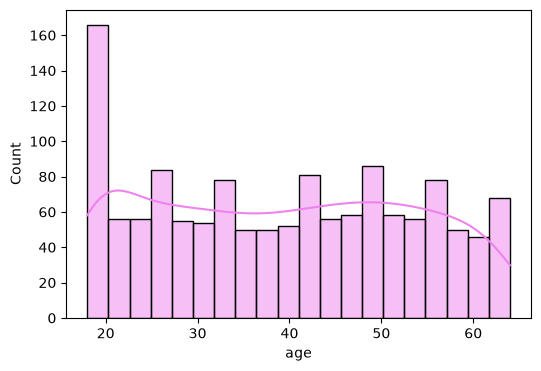

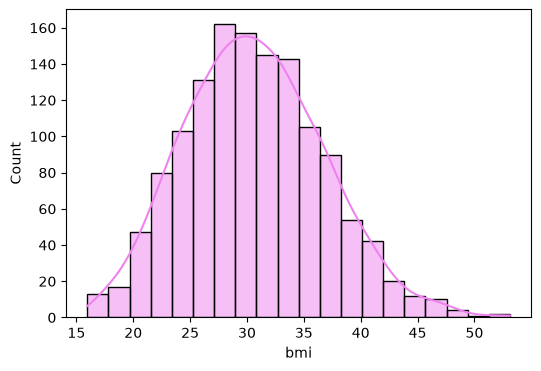

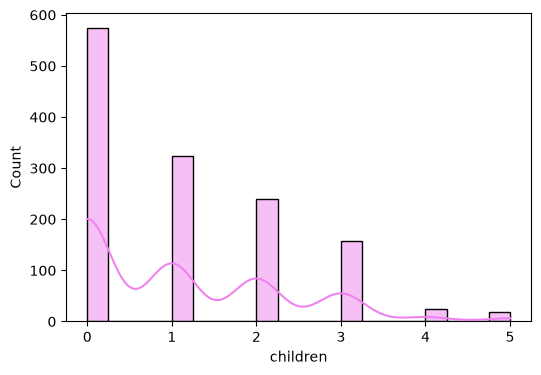

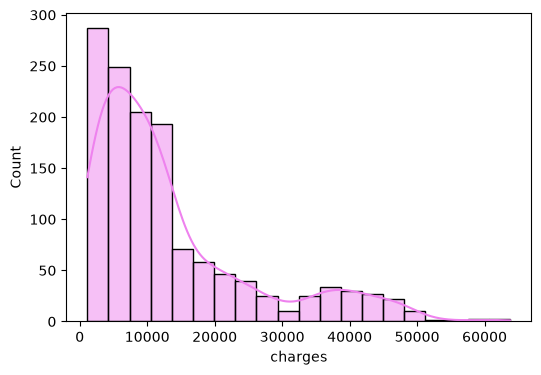

In [9]:
numeric_columns = ['age', 'bmi', 'children', 'charges']

for col in numeric_columns:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True, bins=20, color="violet")

<Axes: xlabel='children', ylabel='count'>

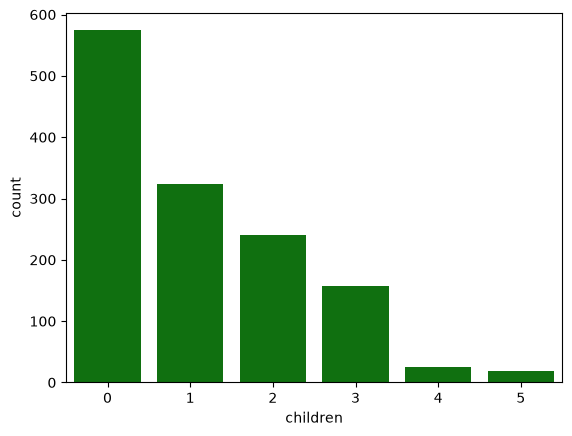

In [10]:
sns.countplot(x = df['children'], color = "green")

<Axes: xlabel='sex', ylabel='count'>

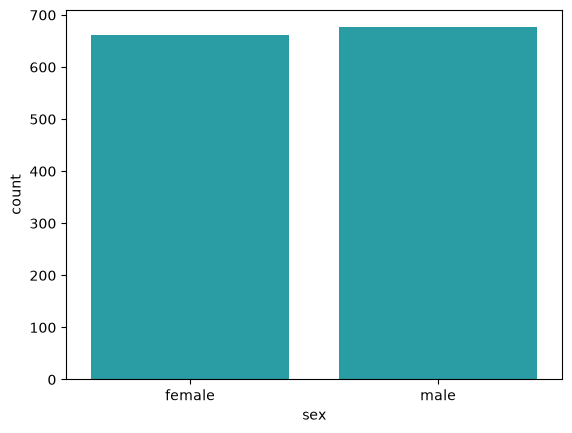

In [11]:
sns.countplot(x = df['sex'], color="#14AEB9")

<Axes: xlabel='smoker', ylabel='count'>

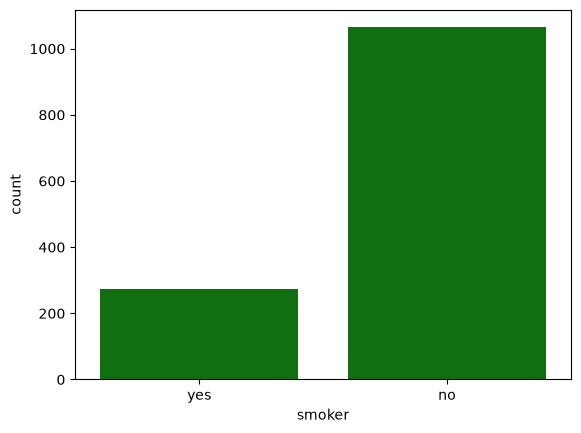

In [12]:
sns.countplot(x = df['smoker'], color="green")

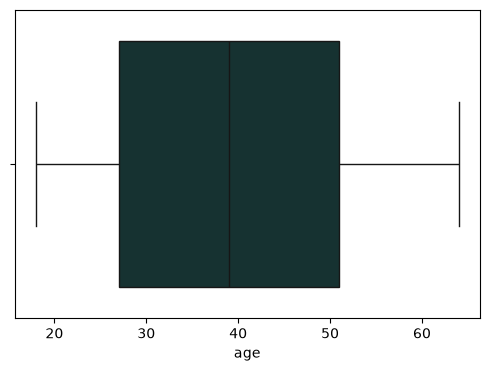

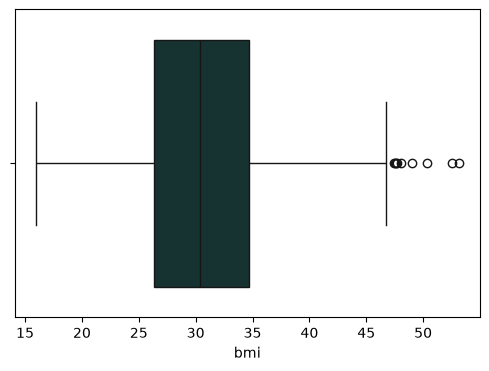

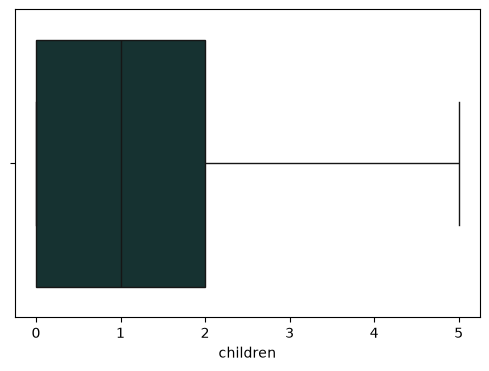

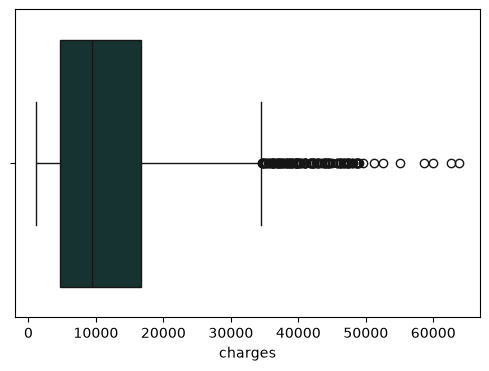

In [13]:
for cols in numeric_columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x = df[cols], color="#123635")

<Axes: >

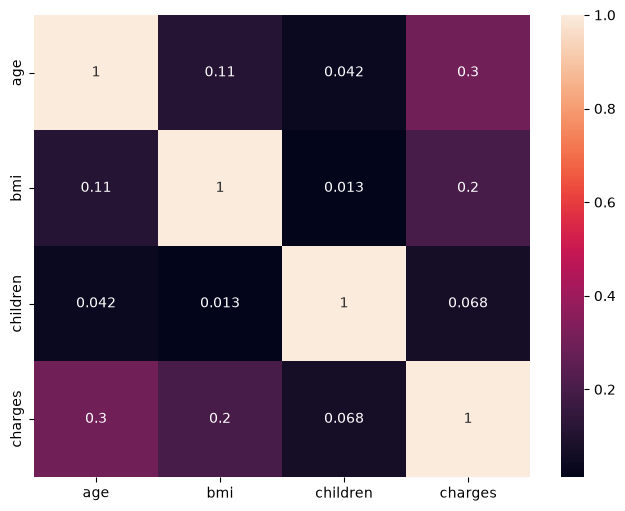

In [14]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True), annot=True)

## Data Cleaning And Preprocessing

In [15]:
df_cleaned = df.copy()

In [16]:
df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [17]:
df_cleaned.shape

(1338, 7)

In [18]:
df_cleaned.drop_duplicates(inplace=True)

In [19]:
df_cleaned.shape

(1337, 7)

In [20]:
df_cleaned.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [21]:
df_cleaned['sex'].value_counts()

sex
male      675
female    662
Name: count, dtype: int64

In [22]:
df_cleaned['sex'] = df_cleaned['sex'].map({"male" : 0, "female" :1})

In [23]:
df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,yes,southwest,16884.92400
1,18,0,33.770,1,no,southeast,1725.55230
2,28,0,33.000,3,no,southeast,4449.46200
3,33,0,22.705,0,no,northwest,21984.47061
4,32,0,28.880,0,no,northwest,3866.85520


In [24]:
# checking if object data got converted to int64
df_cleaned["sex"].dtype

dtype('int64')

In [25]:
df_cleaned["smoker"].value_counts()

smoker
no     1063
yes     274
Name: count, dtype: int64

In [26]:
df_cleaned["smoker"] = df_cleaned["smoker"].map({"no" : 0, "yes" : 1})

In [27]:
df_cleaned["sex"].dtype

dtype('int64')

In [28]:
df_cleaned.rename(columns={
    "sex" : "is_female",
    "smoker" : "is_smoker"
}, inplace=True)

In [29]:
df_cleaned["region"].value_counts()

region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64

In [30]:
df_cleaned =  pd.get_dummies(df_cleaned, columns=['region'], drop_first=True)

In [31]:
df_cleaned

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,False,False,True
1,18,0,33.770,1,0,1725.55230,False,True,False
2,28,0,33.000,3,0,4449.46200,False,True,False
3,33,0,22.705,0,0,21984.47061,True,False,False
4,32,0,28.880,0,0,3866.85520,True,False,False
...,...,...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,10600.54830,True,False,False
1334,18,1,31.920,0,0,2205.98080,False,False,False
1335,18,1,36.850,0,0,1629.83350,False,True,False
1336,21,1,25.800,0,0,2007.94500,False,False,True


In [32]:
df_cleaned = df_cleaned.astype(int)

In [33]:
df_cleaned

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest
0,19,1,27,0,1,16884,0,0,1
1,18,0,33,1,0,1725,0,1,0
2,28,0,33,3,0,4449,0,1,0
3,33,0,22,0,0,21984,1,0,0
4,32,0,28,0,0,3866,1,0,0
...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,1,0,0
1334,18,1,31,0,0,2205,0,0,0
1335,18,1,36,0,0,1629,0,1,0
1336,21,1,25,0,0,2007,0,0,1


## Feature Engineering And Extractions

<Axes: xlabel='bmi', ylabel='Count'>

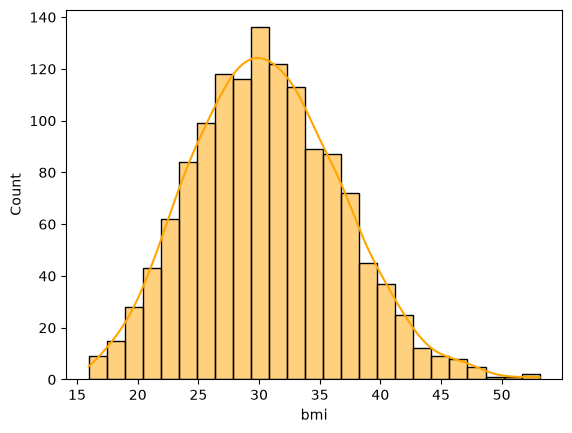

In [34]:
sns.histplot(df['bmi'], color="orange", kde=True)

In [35]:
# changing bmi to cateogry 

df_cleaned['bmi_category'] = pd.cut(
    df_cleaned['bmi'], 
    bins=[0, 18.4, 24.9, 29.9, float('inf')],
    labels = ["Underweight", "HealthyWeight", "Overweight", 'Obesity']
)

In [36]:
df_cleaned

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category
0,19,1,27,0,1,16884,0,0,1,Overweight
1,18,0,33,1,0,1725,0,1,0,Obesity
2,28,0,33,3,0,4449,0,1,0,Obesity
3,33,0,22,0,0,21984,1,0,0,HealthyWeight
4,32,0,28,0,0,3866,1,0,0,Overweight
...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,1,0,0,Obesity
1334,18,1,31,0,0,2205,0,0,0,Obesity
1335,18,1,36,0,0,1629,0,1,0,Obesity
1336,21,1,25,0,0,2007,0,0,1,Overweight


In [37]:
df_cleaned.info()

<class 'pandas.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   age               1337 non-null   int64   
 1   is_female         1337 non-null   int64   
 2   bmi               1337 non-null   int64   
 3   children          1337 non-null   int64   
 4   is_smoker         1337 non-null   int64   
 5   charges           1337 non-null   int64   
 6   region_northwest  1337 non-null   int64   
 7   region_southeast  1337 non-null   int64   
 8   region_southwest  1337 non-null   int64   
 9   bmi_category      1337 non-null   category
dtypes: category(1), int64(9)
memory usage: 106.0 KB


In [38]:
# one-hot encoding
df_cleaned = pd.get_dummies(df_cleaned, columns=["bmi_category"], drop_first=True)

In [39]:
df_cleaned = df_cleaned.astype(int)

In [40]:
df_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_HealthyWeight,bmi_category_Overweight,bmi_category_Obesity
0,19,1,27,0,1,16884,0,0,1,0,1,0
1,18,0,33,1,0,1725,0,1,0,0,0,1
2,28,0,33,3,0,4449,0,1,0,0,0,1
3,33,0,22,0,0,21984,1,0,0,1,0,0
4,32,0,28,0,0,3866,1,0,0,0,1,0


In [41]:
df_cleaned.info()

<class 'pandas.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   age                         1337 non-null   int64
 1   is_female                   1337 non-null   int64
 2   bmi                         1337 non-null   int64
 3   children                    1337 non-null   int64
 4   is_smoker                   1337 non-null   int64
 5   charges                     1337 non-null   int64
 6   region_northwest            1337 non-null   int64
 7   region_southeast            1337 non-null   int64
 8   region_southwest            1337 non-null   int64
 9   bmi_category_HealthyWeight  1337 non-null   int64
 10  bmi_category_Overweight     1337 non-null   int64
 11  bmi_category_Obesity        1337 non-null   int64
dtypes: int64(12)
memory usage: 135.8 KB


In [42]:
df_cleaned.columns

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northwest', 'region_southeast', 'region_southwest',
       'bmi_category_HealthyWeight', 'bmi_category_Overweight',
       'bmi_category_Obesity'],
      dtype='str')

In [43]:
cols = ["age", "bmi", "children"]
scaler = StandardScaler()

df_cleaned[cols] = scaler.fit_transform(df_cleaned[cols])

In [44]:
df_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_HealthyWeight,bmi_category_Overweight,bmi_category_Obesity
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,0,1,0,1,0
1,-1.511647,0,0.462463,-0.079442,0,1725,0,1,0,0,0,1
2,-0.799350,0,0.462463,1.580143,0,4449,0,1,0,0,0,1
3,-0.443201,0,-1.334960,-0.909234,0,21984,1,0,0,1,0,0
4,-0.514431,0,-0.354547,-0.909234,0,3866,1,0,0,0,1,0


In [45]:
## Pearson Correlation Calculation

# features to check against target
selected_features = ['age', 'is_female', 'bmi', 'children', 'is_smoker',
       'region_northwest', 'region_southeast', 'region_southwest',
       'bmi_category_HealthyWeight', 'bmi_category_Overweight',
       'bmi_category_Obesity']

correlation = {
    feature : stats.pearsonr(df_cleaned[feature], df_cleaned['charges'])[0]
    for feature in selected_features
}

correlation_df = pd.DataFrame(list(correlation.items()), columns=["Feature", "Pearson Correlation"])
correlation_df.sort_values(by="Pearson Correlation", ascending=False)

,Feature,Pearson Correlation
4,is_smoker,0.787234
0,age,0.298309
10,bmi_category_Obesity,0.200348
2,bmi,0.196236
6,region_southeast,0.073577
3,children,0.067390
5,region_northwest,-0.038695
7,region_southwest,-0.043637
1,is_female,-0.058046
8,bmi_category_HealthyWeight,-0.104042


In [46]:
cat_features = ['is_female', 'is_smoker',
       'region_northwest', 'region_southeast', 'region_southwest',
       'bmi_category_HealthyWeight', 'bmi_category_Overweight', 'bmi_category_Obesity'
       ]

In [47]:
# chi-square test

from scipy.stats import chi2_contingency

df_cleaned['charges_bin'] = pd.qcut(df['charges'], q=4, labels=False)
chi2_results = {}

alpha = 0.05

for col in cat_features:
    contingency = pd.crosstab(df_cleaned[col], df_cleaned['charges_bin'])
    chi2_stat, p_val, _, _ = chi2_contingency(contingency)
    decision = "Reject Null (Keep Feature)" if p_val < alpha else "Accept Null (Drop Feature)"
    chi2_results[col] = {
        'chi2_stastic' : chi2_stat,
        'p_value' : p_val,
        'Decision' : decision
    }

In [48]:
chi2_results

{'is_female': {'chi2_stastic': np.float64(9.467253404970535),
  'p_value': np.float64(0.02368229313402164),
  'Decision': 'Reject Null (Keep Feature)'},
 'is_smoker': {'chi2_stastic': np.float64(853.2888190740186),
  'p_value': np.float64(1.198625094485044e-184),
  'Decision': 'Reject Null (Keep Feature)'},
 'region_northwest': {'chi2_stastic': np.float64(1.1949883174273581),
  'p_value': np.float64(0.7542065694906167),
  'Decision': 'Accept Null (Drop Feature)'},
 'region_southeast': {'chi2_stastic': np.float64(15.252300237262633),
  'p_value': np.float64(0.0016132546708002495),
  'Decision': 'Reject Null (Keep Feature)'},
 'region_southwest': {'chi2_stastic': np.float64(5.517987889226108),
  'p_value': np.float64(0.13756669221831594),
  'Decision': 'Accept Null (Drop Feature)'},
 'bmi_category_HealthyWeight': {'chi2_stastic': np.float64(3.6611255969975405),
  'p_value': np.float64(0.30045802786785836),
  'Decision': 'Accept Null (Drop Feature)'},
 'bmi_category_Overweight': {'chi2_st

In [49]:
chi2_df = pd.DataFrame(chi2_results).T
chi2_df = chi2_df.sort_values(by='p_value')
chi2_df

,chi2_stastic,p_value,Decision
is_smoker,853.288819,0.0,Reject Null (Keep Feature)
region_southeast,15.2523,0.001613,Reject Null (Keep Feature)
is_female,9.467253,0.023682,Reject Null (Keep Feature)
bmi_category_Obesity,8.689643,0.033715,Reject Null (Keep Feature)
region_southwest,5.517988,0.137567,Accept Null (Drop Feature)
bmi_category_Overweight,4.630431,0.200947,Accept Null (Drop Feature)
bmi_category_HealthyWeight,3.661126,0.300458,Accept Null (Drop Feature)
region_northwest,1.194988,0.754207,Accept Null (Drop Feature)


In [50]:
final_df = df_cleaned[['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_southeast', 'bmi_category_Obesity']]

In [51]:
# cleaned and featured engineered DataFrame
final_df

,age,is_female,bmi,children,is_smoker,charges,region_southeast,bmi_category_Obesity
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,0
1,-1.511647,0,0.462463,-0.079442,0,1725,1,1
2,-0.799350,0,0.462463,1.580143,0,4449,1,1
3,-0.443201,0,-1.334960,-0.909234,0,21984,0,0
4,-0.514431,0,-0.354547,-0.909234,0,3866,0,0
...,...,...,...,...,...,...,...,...
1333,0.767704,0,-0.027743,1.580143,0,10600,0,1
1334,-1.511647,1,0.135659,-0.909234,0,2205,0,1
1335,-1.511647,1,0.952670,-0.909234,0,1629,1,1
1336,-1.297958,1,-0.844753,-0.909234,0,2007,0,0
